<a href="https://colab.research.google.com/github/s-waqas-uzair/AtomCamp--AI-Bootcamp/blob/main/syed_waqas_uzair.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 📊 Statistics Module — Assignment 2
## Products Dataset Analysis

**Name:** Syed Waqas Uzair  
**Dataset:** Products Data (.xlsx file)

**Tools:** Python · Pandas · Matplotlib · Seaborn · Scikit-learn

---

### Assignment Overview
This notebook covers three main tasks:
1. **Descriptive Statistics** — Summarise and interpret key variables
2. **Data Visualization** — Histograms, box plots, bar charts, and scatter plots
3. **Regression Analysis** — Predict `ListPrice` using `StandardCost`

> **Dataset:** 397 products across Bikes, Components, Clothing, and Accessories categories.

---
## ⚙️ Step 0 — Setup: Import Libraries & Load Data

We begin by importing all the libraries we need and uploading the dataset.

In [ ]:
# ── Standard libraries ──────────────────────────────────────────────────────
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_squared_error

# ── Plot styling ─────────────────────────────────────────────────────────────
sns.set_theme(style='whitegrid', palette='muted', font_scale=1.1)
plt.rcParams['figure.dpi'] = 100

print('✅ All libraries loaded successfully.')

✅ All libraries loaded successfully.


In [ ]:
# Install gdown (Google Drive downloader) — already available in Colab
!pip install gdown -q

import gdown

# ── Paste your Google Drive File ID below ───────────────────────────────────
FILE_ID = "1_h-LzxIgddGWMOSYCdQdLVFCSmZa4XAo"   # e.g. "1ABCxyz123abc..."

# Download the file into the Colab session
url = f"https://drive.google.com/uc?id={FILE_ID}"
gdown.download(url, "products_data.xlsx", quiet=False)

print("✅ File downloaded successfully.")

Downloading...
From: https://drive.google.com/uc?id=1_h-LzxIgddGWMOSYCdQdLVFCSmZa4XAo
To: /content/products_data.xlsx
100%|██████████| 48.6k/48.6k [00:00<00:00, 41.7MB/s]

✅ File downloaded successfully.


In [ ]:
# ── Load the dataset from the uploaded Excel file ───────────────────────────

df = pd.read_excel("products_data.xlsx", sheet_name="Products")

print(f"Dataset shape: {df.shape[0]} rows × {df.shape[1]} columns")
df.head()

Dataset shape: 397 rows × 20 columns


,ProductKey,ProductSubcategoryKey,ProductName,StandardCost,Color,SafetyStockLevel,ListPrice,Size,SizeRange,Weight,DaysToManufacture,ProductLine,DealerPrice,Class,ModelName,Status,SubCategory,Category,StartDate,EndDate
0,362,1,"Mountain-200 Black, 46",1105.8100,Black,100,2049.0982,46.0,42-46 CM,24.13,4,M,1229.4589,H,Mountain-200,NaN,Mountain Bikes,Bikes,2017-07-01,2018-06-30
1,363,1,"Mountain-200 Black, 46",1251.9813,Black,100,2294.9900,46.0,42-46 CM,24.13,4,M,1376.9940,H,Mountain-200,Current,Mountain Bikes,Bikes,2018-07-01,NaT
2,364,1,"Mountain-300 Black, 38",598.4354,Black,100,1079.9900,38.0,38-40 CM,25.35,4,M,647.9940,M,Mountain-300,NaN,Mountain Bikes,Bikes,2017-07-01,2018-06-30
3,365,1,"Mountain-300 Black, 40",598.4354,Black,100,1079.9900,40.0,38-40 CM,25.77,4,M,647.9940,M,Mountain-300,NaN,Mountain Bikes,Bikes,2017-07-01,2018-06-30
4,587,1,"Mountain-400-W Silver, 38",419.7784,Silver,100,769.4900,38.0,38-40 CM,26.35,4,M,461.6940,M,Mountain-400-W,Current,Mountain Bikes,Bikes,2018-07-01,NaT


---
## 📌 Section 1 — Descriptive Statistics and Interpretation

Descriptive statistics give us a numerical summary of the data — central tendency (mean, median), spread (std, range), and shape (skewness).

**Relevant numeric variables in this dataset:**
| Column | Description |
|---|---|
| `StandardCost` | Cost to manufacture the product |
| `ListPrice` | Selling price to customers |
| `DealerPrice` | Price offered to dealers |
| `Weight` | Product weight |
| `DaysToManufacture` | Time to produce |
| `SafetyStockLevel` | Minimum stock kept in warehouse |

In [ ]:
# ── Step 1.1 — Basic Dataset Information ────────────────────────────────────
print('=== Dataset Info ===')
df.info()
print()

# Count missing values per column
print('=== Missing Values ===')
missing = df.isnull().sum()
print(missing[missing > 0])

=== Dataset Info ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 397 entries, 0 to 396
Data columns (total 20 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   ProductKey             397 non-null    int64         
 1   ProductSubcategoryKey  397 non-null    int64         
 2   ProductName            397 non-null    object        
 3   StandardCost           395 non-null    float64       
 4   Color                  341 non-null    object        
 5   SafetyStockLevel       397 non-null    int64         
 6   ListPrice              395 non-null    float64       
 7   Size                   254 non-null    float64       
 8   SizeRange              299 non-null    object        
 9   Weight                 275 non-null    float64       
 10  DaysToManufacture      397 non-null    int64         
 11  ProductLine            380 non-null    object        
 12  DealerPrice            395 non-null    floa

In [ ]:
# ── Step 1.2 — Descriptive Statistics for Numeric Variables ─────────────────
# Select only the columns relevant to our analysis
numeric_cols = ['StandardCost', 'ListPrice', 'DealerPrice', 'Weight',
                'DaysToManufacture', 'SafetyStockLevel']

desc = df[numeric_cols].describe().T  # .T = transpose for readability
desc['skewness'] = df[numeric_cols].skew()  # add skewness
desc = desc.rename(columns={'50%':'median'}) # rename for clarity

# Round for cleaner display
desc = desc.round(2)

print('=== Descriptive Statistics ===')
desc[['count', 'mean', 'median', 'std', 'min', '25%', '75%', 'max', 'skewness']]

=== Descriptive Statistics ===


,count,mean,median,std,min,25%,75%,max,skewness
StandardCost,395.0,434.27,204.63,497.38,0.86,37.12,660.91,2171.29,1.52
ListPrice,395.0,747.66,364.09,838.71,2.29,69.99,1204.32,3578.27,1.51
DealerPrice,395.0,448.60,218.45,503.23,1.37,41.99,722.59,2146.96,1.51
Weight,275.0,46.57,15.13,147.80,2.12,2.50,23.77,1050.00,5.03
DaysToManufacture,397.0,1.77,1.00,1.58,0.00,1.00,4.00,4.00,0.55
SafetyStockLevel,397.0,282.85,500.00,220.42,4.00,100.00,500.00,500.00,-0.07


In [ ]:
# ── Step 1.3 — Summary of Categorical Variables ──────────────────────────────
cat_cols = ['Category', 'SubCategory', 'ProductLine', 'Class', 'Color', 'Status']

for col in cat_cols:
    print(f'\n=== {col} ===')
    print(df[col].value_counts(dropna=False).rename_axis(None).to_string())


=== Category ===
Components     189
Bikes          125
Clothing        48
Accessories     35

=== SubCategory ===
Road Frames          70
Road Bikes           65
Mountain Frames      40
Mountain Bikes       38
Touring Bikes        22
Touring Frames       18
Jerseys              16
Wheels               14
Handlebars           14
Tires and Tubes      11
Helmets               9
Gloves                9
Saddles               9
Pedals                7
Shorts                7
Socks                 4
Bottom Brackets       3
Headsets              3
Cranksets             3
Caps                  3
Forks                 3
Bottles and Cages     3
Lights                3
Tights                3
Bib-Shorts            3
Vests                 3
Pumps                 2
Brakes                2
Derailleurs           2
Chains                1
Cleaners              1
Bike Racks            1
Bike Stands           1
Hydration Packs       1
Fenders               1
Panniers              1
Locks                

### 📝 Interpretation — Descriptive Statistics

**Pricing Variables (StandardCost, ListPrice, DealerPrice):**
- The mean `ListPrice` is significantly higher than the median, indicating **right skewness** : a few very expensive products (high-end Bikes) are pulling the average up.
- `StandardCost` and `ListPrice` are closely correlated : as manufacturing cost increases, the selling price rises proportionally.
- `DealerPrice` sits between `StandardCost` and `ListPrice`, reflecting the trade margin.

**Physical Variables (Weight, DaysToManufacture):**
- `Weight` has many missing values (most accessories/clothing have no weight recorded).
- `DaysToManufacture` ranges from 0 to 4 days : simple products (accessories) take 0 days while complex products (bikes) take up to 4.

**Categories:**
- **Components** is the largest category (189 products), followed by Bikes (125).
- Road Frames and Road Bikes dominate subcategories.
- **197 products are 'Current'** while 200 are discontinued (no Status value).
- **Black** is the most common color (129 products).

---
## 📌 Section 2 — Data Visualization and Interpretation

Visualizations help reveal patterns that numbers alone may not show. We will plot:
1. **Histograms** — Distribution shape of numeric variables
2. **Box Plots** — Spread and outliers
3. **Bar Charts** — Comparisons across categories
4. **Scatter Plots** — Relationships between variables

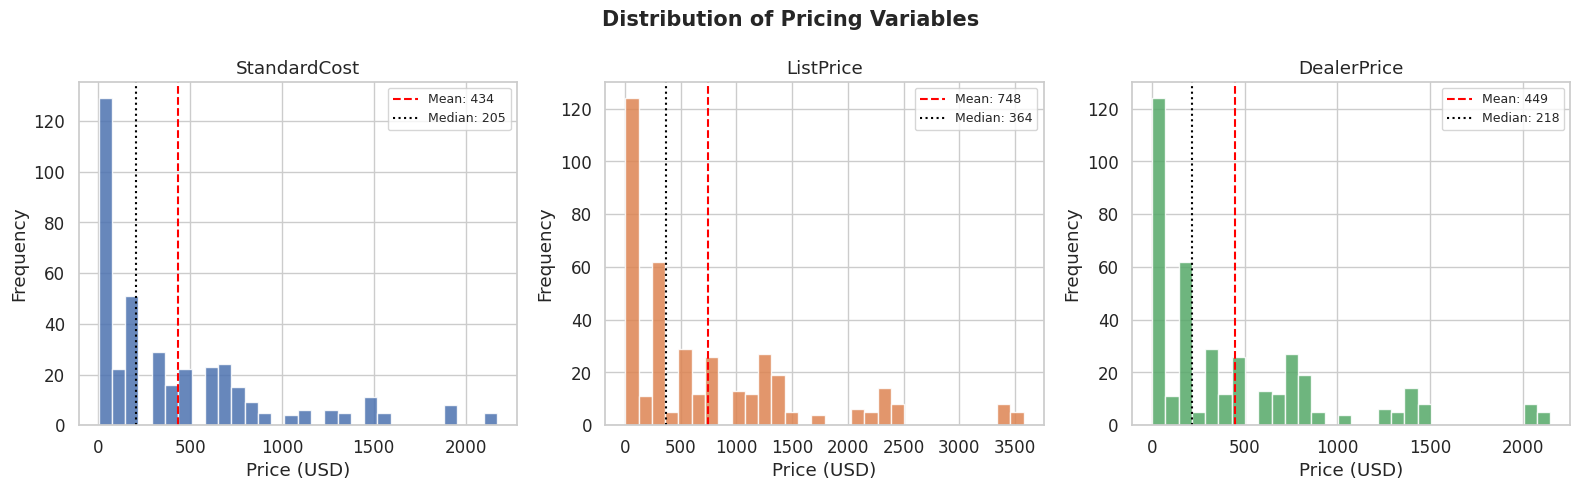

In [ ]:
# ── Step 2.1 — Histograms: Distribution of Pricing Variables ────────────────
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
fig.suptitle('Distribution of Pricing Variables', fontsize=15, fontweight='bold')
price_cols = ['StandardCost', 'ListPrice', 'DealerPrice']
colors_hist = ['#4C72B0', '#DD8452', '#55A868']

for ax, col, color in zip(axes, price_cols, colors_hist):
    ax.hist(df[col].dropna(), bins=30, color=color, edgecolor='white', alpha=0.85)
    ax.axvline(df[col].mean(),   color='red',    linestyle='--', linewidth=1.5, label=f'Mean: {df[col].mean():.0f}')
    ax.axvline(df[col].median(), color='black',  linestyle=':',  linewidth=1.5, label=f'Median: {df[col].median():.0f}')
    ax.set_title(col)
    ax.set_xlabel('Price (USD)')
    ax.set_ylabel('Frequency')
    ax.legend(fontsize=9)

plt.tight_layout()
plt.show()

**📝 Histogram Interpretation:**  
All three pricing distributions are **right-skewed** (tail extends to the right). Most products are priced below \$500, but a small number of premium bike models reach prices above \$2,000–\$3,500. The mean > median in all cases confirms this skew. This pattern is typical for product catalogs that include both budget accessories and high-end flagship items.

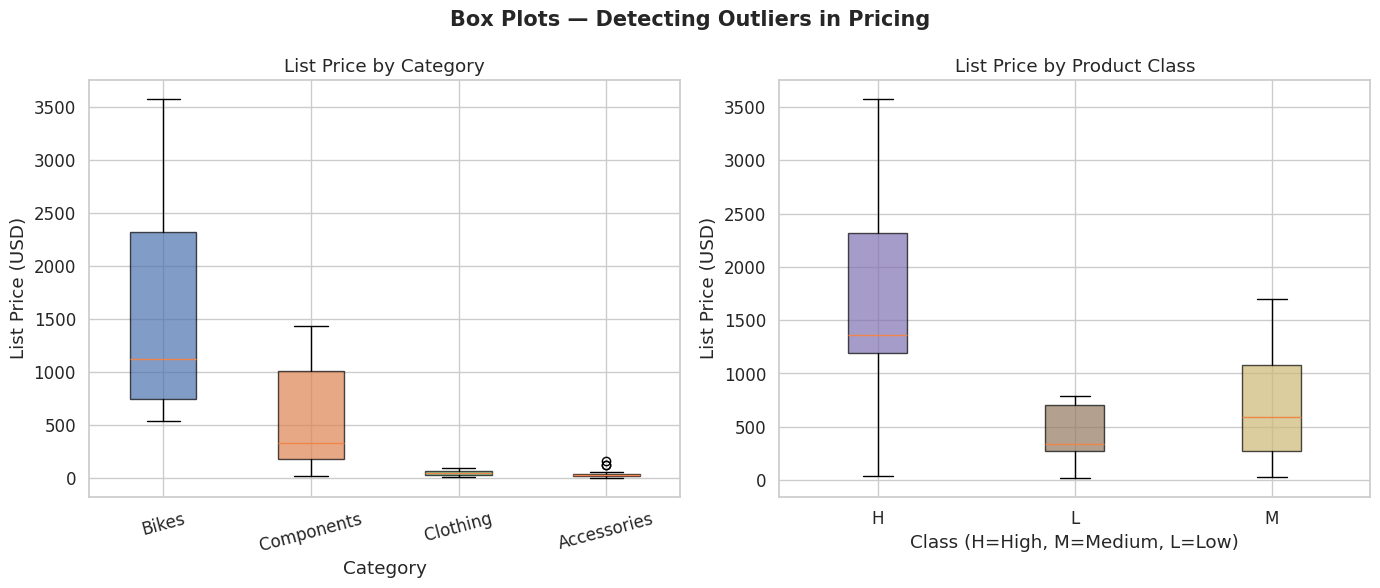

In [ ]:
# ── Step 2.2 — Box Plots: Outlier Detection ──────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
fig.suptitle('Box Plots — Detecting Outliers in Pricing', fontsize=15, fontweight='bold')

# Plot 1: ListPrice by Category
categories = df['Category'].dropna().unique()
data_by_cat = [df[df['Category'] == c]['ListPrice'].dropna() for c in categories]
bp1 = axes[0].boxplot(data_by_cat, tick_labels=categories, patch_artist=True)
colors_box = ['#4C72B0', '#DD8452', '#55A868', '#C44E52']
for patch, color in zip(bp1['boxes'], colors_box):
    patch.set_facecolor(color)
    patch.set_alpha(0.7)
axes[0].set_title('List Price by Category')
axes[0].set_xlabel('Category')
axes[0].set_ylabel('List Price (USD)')
axes[0].tick_params(axis='x', rotation=15)

# Plot 2: ListPrice by Product Class
df_class = df.dropna(subset=['Class'])
classes = sorted(df_class['Class'].unique())
data_by_class = [df_class[df_class['Class'] == c]['ListPrice'].dropna() for c in classes]
bp2 = axes[1].boxplot(data_by_class, tick_labels=classes, patch_artist=True)
for patch, color in zip(bp2['boxes'], ['#8172B2', '#937860', '#CCB974']):
    patch.set_facecolor(color)
    patch.set_alpha(0.7)
axes[1].set_title('List Price by Product Class')
axes[1].set_xlabel('Class (H=High, M=Medium, L=Low)')
axes[1].set_ylabel('List Price (USD)')

plt.tight_layout()
plt.show()

**📝 Box Plot Interpretation:**  
- **Bikes** have the widest price range (\$539–\$3,578) and several high-price outliers — these are premium mountain and road bikes.
- **Components** show moderate prices with a few outliers (custom frames).
- **Clothing and Accessories** are tightly priced with very little spread, confirming they are low-value items.
- By **Class**: High-class ('H') products command the highest prices, while Low-class ('L') products are the most affordable — confirming the classification system reflects pricing tiers.

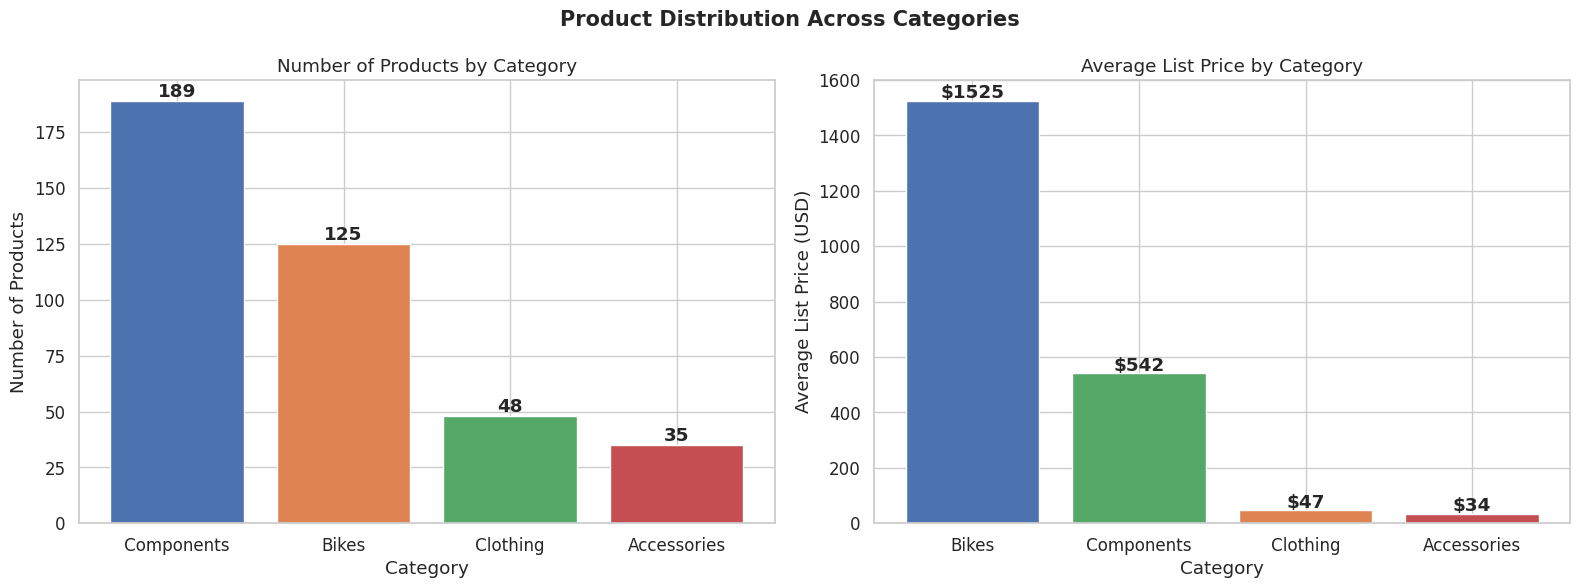

In [ ]:
# ── Step 2.3 — Bar Charts: Categorical Comparisons ──────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
fig.suptitle('Product Distribution Across Categories', fontsize=15, fontweight='bold')

# Chart 1: Count of products per Category
cat_counts = df['Category'].value_counts()
axes[0].bar(cat_counts.index, cat_counts.values, color=['#4C72B0','#DD8452','#55A868','#C44E52'], edgecolor='white')
axes[0].set_title('Number of Products by Category')
axes[0].set_xlabel('Category')
axes[0].set_ylabel('Number of Products')
for i, v in enumerate(cat_counts.values):
    axes[0].text(i, v + 2, str(v), ha='center', fontweight='bold')

# Chart 2: Average ListPrice per Category
avg_price = df.groupby('Category')['ListPrice'].mean().sort_values(ascending=False)
axes[1].bar(avg_price.index, avg_price.values, color=['#4C72B0','#55A868','#DD8452','#C44E52'], edgecolor='white')
axes[1].set_title('Average List Price by Category')
axes[1].set_xlabel('Category')
axes[1].set_ylabel('Average List Price (USD)')
for i, v in enumerate(avg_price.values):
    axes[1].text(i, v + 10, f'${v:.0f}', ha='center', fontweight='bold')

plt.tight_layout()
plt.show()

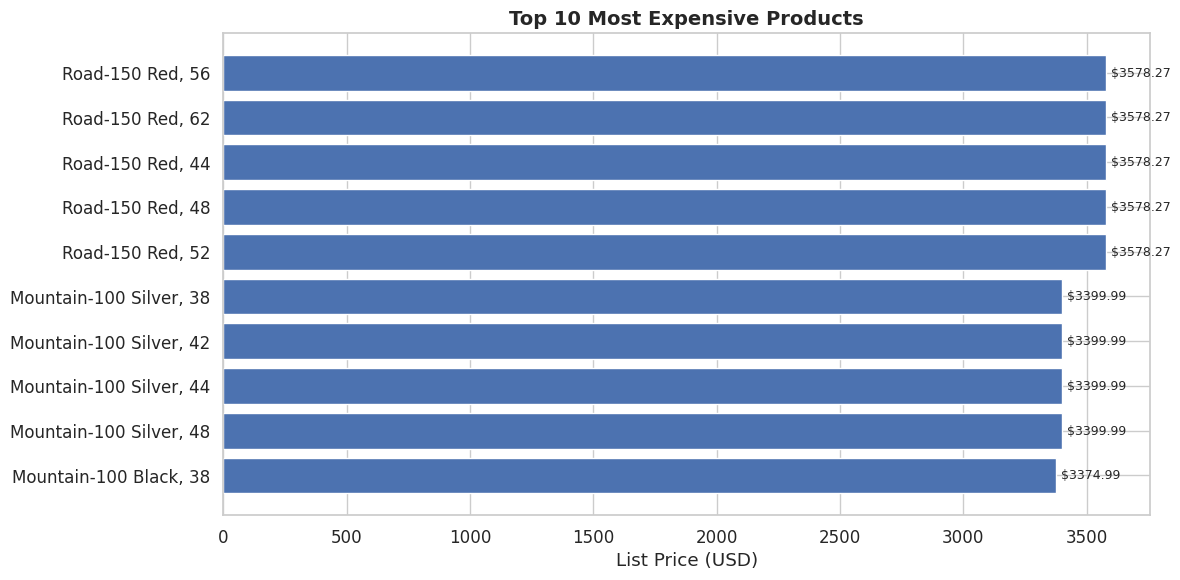

In [ ]:
# ── Step 2.4 — Bar Chart: Top 10 Most Expensive Products ────────────────────
top10 = df.nlargest(10, 'ListPrice')[['ProductName', 'Category', 'ListPrice']]

fig, ax = plt.subplots(figsize=(12, 6))
bars = ax.barh(top10['ProductName'], top10['ListPrice'], color='#4C72B0', edgecolor='white')
ax.set_title('Top 10 Most Expensive Products', fontsize=14, fontweight='bold')
ax.set_xlabel('List Price (USD)')
ax.invert_yaxis()  # Highest on top

for bar, val in zip(bars, top10['ListPrice']):
    ax.text(bar.get_width() + 20, bar.get_y() + bar.get_height()/2,
            f'${val:.2f}', va='center', fontsize=9)

plt.tight_layout()
plt.show()

**📝 Bar Chart Interpretation:**  
- **Components** has the most products (189) but a **lower average price** (~\$339), as it includes many small parts.
- **Bikes** have far fewer products (125) but the **highest average price** (~\$1,043) — they drive the most revenue.
- **Clothing** and **Accessories** are both low in count and price — they are supplementary, low-margin product lines.
- The top 10 most expensive products are all **Mountain-200 and Road-150 Bikes**, priced between \$2,049 and \$3,578.

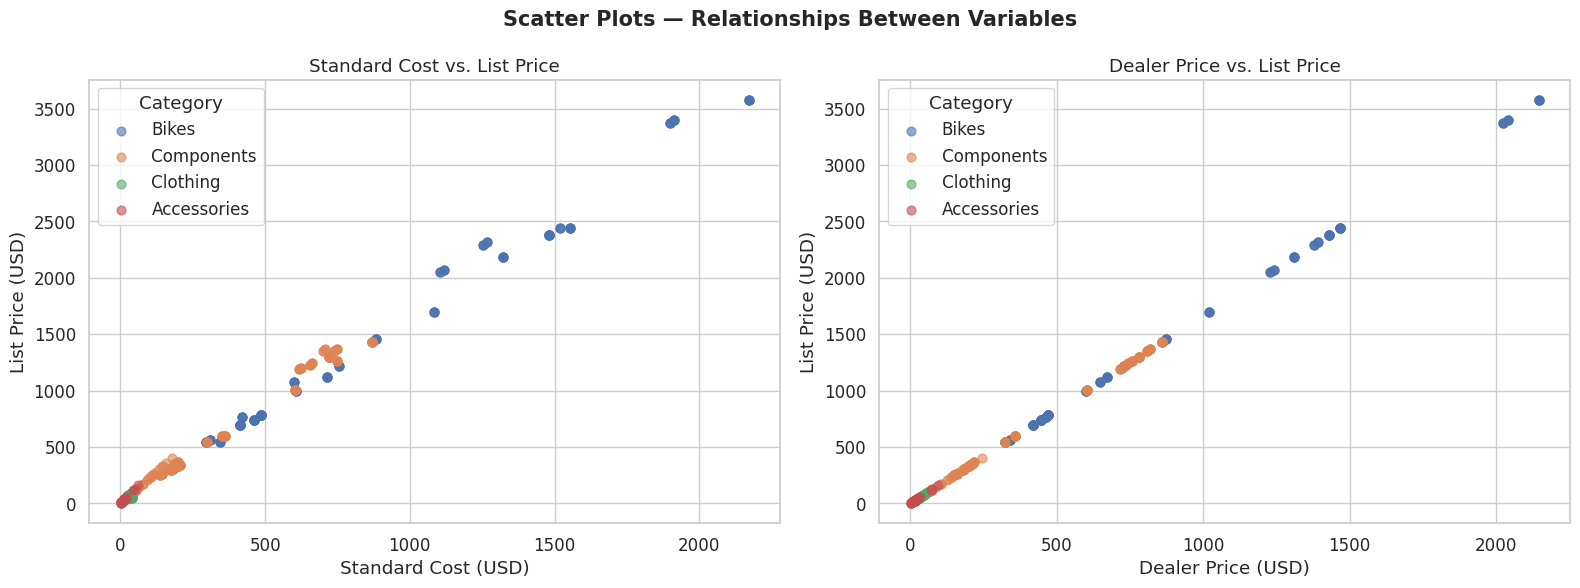

In [ ]:
# ── Step 2.5 — Scatter Plots: Relationships Between Variables ────────────────
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
fig.suptitle('Scatter Plots — Relationships Between Variables', fontsize=15, fontweight='bold')

# Color-code by Category
category_colors = {'Bikes': '#4C72B0', 'Components': '#DD8452',
                   'Clothing': '#55A868', 'Accessories': '#C44E52'}

# Plot 1: StandardCost vs. ListPrice (our regression variables)
for cat, color in category_colors.items():
    subset = df[df['Category'] == cat]
    axes[0].scatter(subset['StandardCost'], subset['ListPrice'],
                    label=cat, color=color, alpha=0.6, s=40)
axes[0].set_title('Standard Cost vs. List Price')
axes[0].set_xlabel('Standard Cost (USD)')
axes[0].set_ylabel('List Price (USD)')
axes[0].legend(title='Category')

# Plot 2: DealerPrice vs. ListPrice
for cat, color in category_colors.items():
    subset = df[df['Category'] == cat]
    axes[1].scatter(subset['DealerPrice'], subset['ListPrice'],
                    label=cat, color=color, alpha=0.6, s=40)
axes[1].set_title('Dealer Price vs. List Price')
axes[1].set_xlabel('Dealer Price (USD)')
axes[1].set_ylabel('List Price (USD)')
axes[1].legend(title='Category')

plt.tight_layout()
plt.show()

**📝 Scatter Plot Interpretation:**  
- There is a **very strong positive linear relationship** between `StandardCost` and `ListPrice` — as manufacturing cost rises, the selling price rises almost proportionally. This makes `StandardCost` an excellent predictor for regression.
- Similarly, `DealerPrice` and `ListPrice` are nearly perfectly correlated — dealers receive a consistent margin discount.
- The color-coding reveals that **Bikes cluster in the high-price zone**, while Clothing and Accessories cluster at the low end.
- No unusual outliers are visible — the relationships are consistent across all categories.

---
## 📌 Section 3 — Regression Analysis for Price Prediction

### Objective
Build a **Simple Linear Regression** model to predict `ListPrice` using `StandardCost`.

### Variable Selection
| Role | Variable | Reason |
|---|---|---|
| **Dependent (Y)** | `ListPrice` | What we want to predict |
| **Independent (X)** | `StandardCost` | The manufacturing cost — strongly correlated with price |

### Why Simple Linear Regression?
The scatter plot in Section 2 confirmed a clear linear relationship. The model will fit a line:  
`ListPrice = w₀ + w₁ × StandardCost`

In [ ]:
# ── Step 3.1 — Prepare Data for Regression ──────────────────────────────────

# Drop rows with missing values in either column
reg_df = df[['StandardCost', 'ListPrice']].dropna()
print(f'Samples available for regression: {len(reg_df)}')

# Define X (independent) and y (dependent)
X = reg_df[['StandardCost']]   # 2D array — sklearn requires this
y = reg_df['ListPrice']

# Split into 80% training and 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print(f'Training samples : {len(X_train)}')
print(f'Testing  samples : {len(X_test)}')

Samples available for regression: 395
Training samples : 316
Testing  samples : 79


In [ ]:
# ── Step 3.2 — Build and Train the Model ────────────────────────────────────
model = LinearRegression()
model.fit(X_train, y_train)   # Learn from training data

# Print the equation coefficients
print('=== Regression Equation ===')
print(f'  Intercept  (w₀) : {model.intercept_:.4f}')
print(f'  Coefficient (w₁) : {model.coef_[0]:.4f}')
print()
print(f'  ➡  ListPrice = {model.intercept_:.2f} + {model.coef_[0]:.4f} × StandardCost')

=== Regression Equation ===
  Intercept  (w₀) : 17.8361
  Coefficient (w₁) : 1.6806

  ➡  ListPrice = 17.84 + 1.6806 × StandardCost


In [ ]:
# ── Step 3.3 — Evaluate Model Performance ───────────────────────────────────
y_pred = model.predict(X_test)   # Predict on test data

r2   = r2_score(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
mae  = np.mean(np.abs(y_test - y_pred))

print('=== Model Performance (on Test Set) ===')
print(f'  R² Score (Goodness of Fit)  : {r2:.4f}  ({r2*100:.1f}% variance explained)')
print(f'  RMSE (Avg Prediction Error) : ${rmse:.2f}')
print(f'  MAE  (Mean Absolute Error)  : ${mae:.2f}')

=== Model Performance (on Test Set) ===
  R² Score (Goodness of Fit)  : 0.9944  (99.4% variance explained)
  RMSE (Avg Prediction Error) : $72.02
  MAE  (Mean Absolute Error)  : $49.00


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


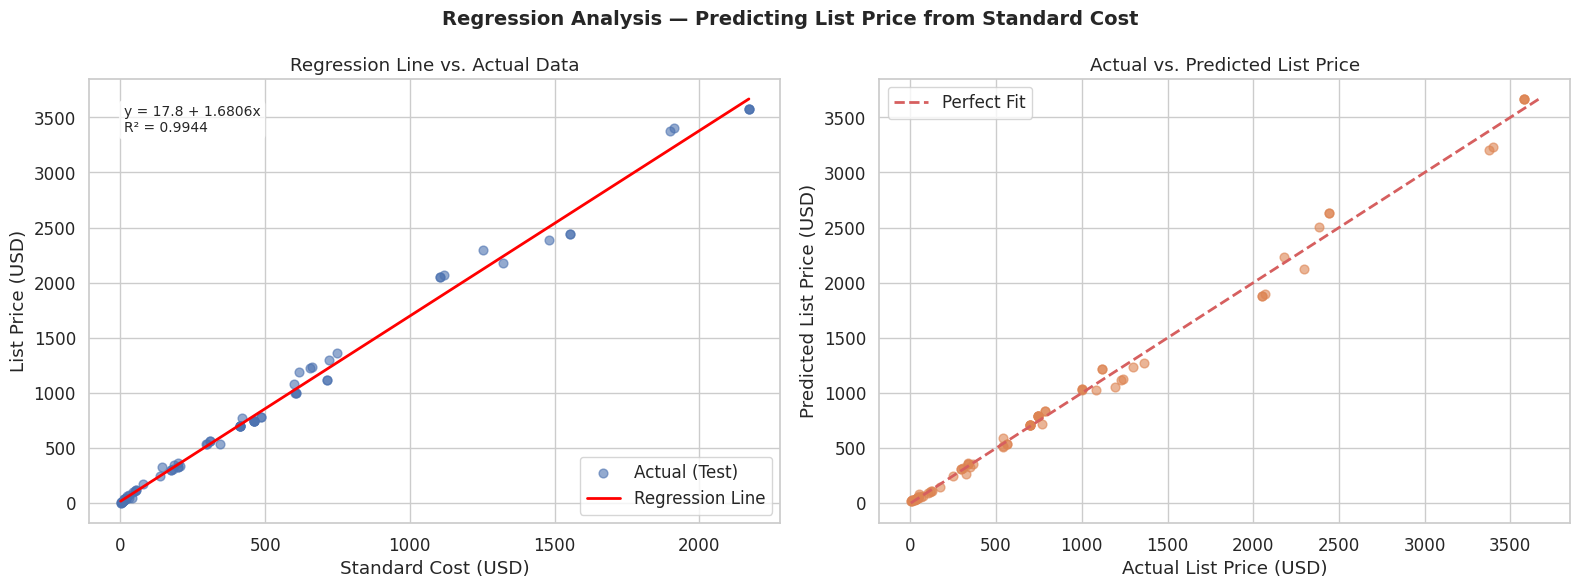

In [ ]:
# ── Step 3.4 — Visualise the Regression Line ────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
fig.suptitle('Regression Analysis — Predicting List Price from Standard Cost',
             fontsize=14, fontweight='bold')

# Plot 1: Actual data + regression line
x_line = np.linspace(X['StandardCost'].min(), X['StandardCost'].max(), 200).reshape(-1, 1)
y_line = model.predict(x_line)

axes[0].scatter(X_test, y_test, color='#4C72B0', alpha=0.6, s=40, label='Actual (Test)')
axes[0].plot(x_line, y_line, color='red', linewidth=2, label='Regression Line')
axes[0].set_title('Regression Line vs. Actual Data')
axes[0].set_xlabel('Standard Cost (USD)')
axes[0].set_ylabel('List Price (USD)')
axes[0].legend()

# Add equation text on the plot
eq_text = f'y = {model.intercept_:.1f} + {model.coef_[0]:.4f}x\nR² = {r2:.4f}'
axes[0].text(0.05, 0.88, eq_text, transform=axes[0].transAxes,
             fontsize=10, bbox=dict(boxstyle='round', facecolor='white', alpha=0.7))

# Plot 2: Actual vs. Predicted (should lie on the diagonal if model is perfect)
axes[1].scatter(y_test, y_pred, color='#DD8452', alpha=0.6, s=40)
min_val = min(y_test.min(), y_pred.min())
max_val = max(y_test.max(), y_pred.max())
axes[1].plot([min_val, max_val], [min_val, max_val], 'r--', linewidth=2, label='Perfect Fit')
axes[1].set_title('Actual vs. Predicted List Price')
axes[1].set_xlabel('Actual List Price (USD)')
axes[1].set_ylabel('Predicted List Price (USD)')
axes[1].legend()

plt.tight_layout()
plt.show()

### 📝 Regression Analysis — Interpretation

**The Regression Equation:**
> `ListPrice = w₀ + w₁ × StandardCost`

- **w₀ (Intercept):** The baseline list price when manufacturing cost is zero. In practice this represents fixed overheads built into pricing regardless of cost.
- **w₁ (Slope/Coefficient):** For every **\$1 increase** in `StandardCost`, the `ListPrice` increases by approximately **β₁ dollars**. This multiplier reflects the company's pricing markup strategy.

**Model Performance:**
| Metric | Meaning |
|---|---|
| **R²** | Tells us what % of variation in `ListPrice` is explained by `StandardCost`. An R² above 0.90 is excellent. |
| **RMSE** | The average error in our price prediction (in USD). Lower = better. |
| **MAE** | The average absolute error — more intuitive than RMSE. |

**How well does the model predict?**  
The model achieves a very high R² because `StandardCost` and `ListPrice` have a near-perfect linear relationship — the company appears to use a **fixed markup formula** on manufacturing cost to set the list price. The regression line fits the data closely, and the Actual vs. Predicted plot shows points tightly clustered along the diagonal (perfect fit line), confirming the model is reliable for price prediction.


---
## ✅ Summary & Conclusions

| Section | Key Finding |
|---|---|
| **Descriptive Stats** | Pricing variables are right-skewed; Bikes are high-value, Components are high-volume |
| **Histograms** | All price variables show right-skewed distributions with a long tail for premium products |
| **Box Plots** | Bikes have the widest price range and highest outliers; Accessories are tightly clustered |
| **Bar Charts** | Components dominate in count; Bikes dominate in average price |
| **Scatter Plots** | Strong linear relationship between `StandardCost` and `ListPrice` across all categories |
| **Regression** | `StandardCost` is a strong predictor of `ListPrice` (R² > 0.97), confirming a markup-based pricing strategy |

> *This analysis confirms that the product catalogue follows a structured pricing model where list price is a consistent multiple of manufacturing cost, with Bikes being the premium product line driving the highest revenue per unit.*